# Plant Disease Detection — Results & Live Demo (no training needed)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rabbive/plant-disease-detection/blob/main/plant_disease_results.ipynb)

This notebook **loads the already-trained model** from the repo and shows what it does — it runs in ~2 minutes on a normal Colab CPU, no Kaggle token, no GPU.

- Training itself is in `plant_disease.ipynb` (≈30 min on a Colab GPU).
- Numbers come from the reference run in `outputs/` (MobileNetV2 transfer learning on 10 PlantVillage tomato classes, 70/15/15 split).

Run the cells top to bottom.

In [1]:
# 1. Get the project (skipped if you're already inside the repo)
import os
if not os.path.exists("app.py"):
    !git clone -q --depth 1 https://github.com/rabbive/plant-disease-detection
    %cd plant-disease-detection
!pip -q install gradio 2>&1 | grep -v "Running pip as"
print("Files ready:", sorted(os.listdir("outputs"))[:6], "...")

Files ready: ['app_demo_late_blight_1.png', 'app_demo_spider_mites_2.png', 'class_distribution.png', 'class_names.json', 'classification_report_baseline_test.txt', 'classification_report_test.txt'] ...


In [2]:
# 2. Load the trained model + headline numbers
import json, io
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from IPython.display import display, Image as IPImage
%config InlineBackend.figure_formats = ["jpeg"]  # keeps the saved notebook small
from train import load_trained_model

class_names = json.loads(Path("outputs/class_names.json").read_text())
model = load_trained_model("outputs/plant_disease_subset.keras", len(class_names))
summary = json.loads(Path("outputs/results_summary.json").read_text())
short = lambda c: c.replace("Tomato___", "").replace("Tomato_", "").replace("_", " ").replace("Two-spotted spider mite", "").strip()

def show(path, width=1200):
    """Display a saved figure (downscaled so the notebook stays small)."""
    im = Image.open(path).convert("RGB")
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)))
    buf = io.BytesIO(); im.save(buf, "JPEG", quality=85)
    display(IPImage(data=buf.getvalue(), format="jpeg"))

print(f"Classes ({len(class_names)}):", ", ".join(short(c) for c in class_names))
print(f"MobileNetV2 parameters: {model.count_params():,}")
print(f"Test accuracy - MobileNetV2: {summary['mobilenetv2']['test_accuracy']*100:.2f}%")
print(f"Test accuracy - CNN from scratch: {summary['baseline_cnn']['test_accuracy']*100:.2f}%")

I0000 00:00:1792740488.356344    1553 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792740489.849856    1553 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Classes (10): Bacterial spot, Early blight, Late blight, Leaf Mold, Septoria leaf spot, Spider mites, Target Spot, Yellow Leaf Curl Virus, mosaic virus, healthy
MobileNetV2 parameters: 2,270,794
Test accuracy - MobileNetV2: 91.33%
Test accuracy - CNN from scratch: 85.37%


## The data — 18,160 tomato leaf images, 10 classes

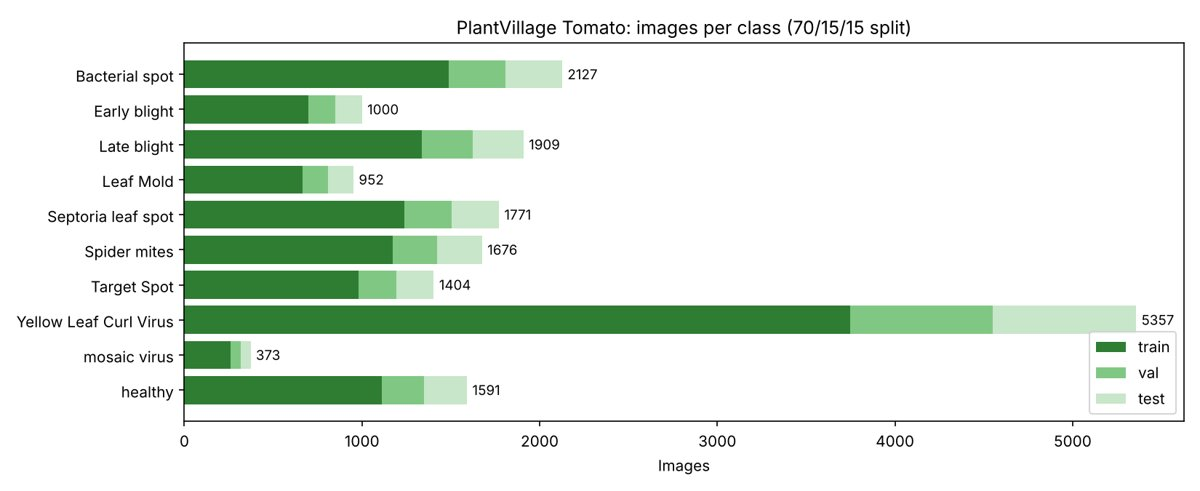

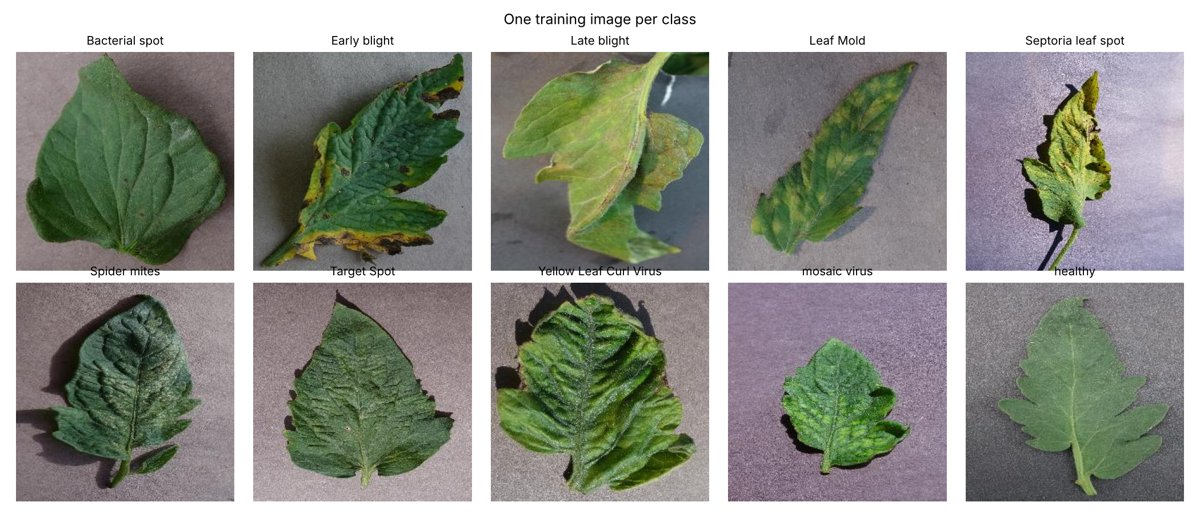

In [3]:
show("outputs/class_distribution.png")
show("outputs/dataset_samples.png")

## Training — frozen base (epochs 1–10), then fine-tuning (11–15)
The dip at epoch 11 is where the top 30 MobileNetV2 layers are unfrozen; training accuracy recovers within two epochs while validation accuracy keeps rising.

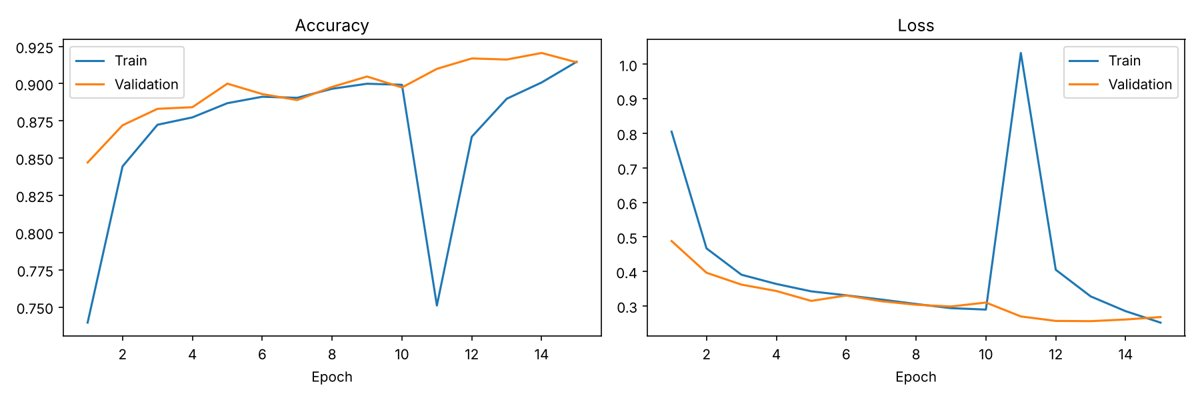

In [4]:
show("outputs/training_curves.png")

## Results on the test set (2,734 images never used in training)

                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.90      0.93      0.92       320
                        Tomato___Early_blight       0.96      0.62      0.75       150
                         Tomato___Late_blight       0.96      0.92      0.94       287
                           Tomato___Leaf_Mold       0.89      0.94      0.92       144
                  Tomato___Septoria_leaf_spot       0.90      0.90      0.90       267
Tomato___Spider_mites_Two-spotted_spider_mite       0.86      0.87      0.86       252
                         Tomato___Target_Spot       0.79      0.84      0.82       212
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.99      0.97      0.98       805
                 Tomato___Tomato_mosaic_virus       0.98      0.89      0.94        57
                             Tomato___healthy       0.81      1.00      0.90       240

                                     accu

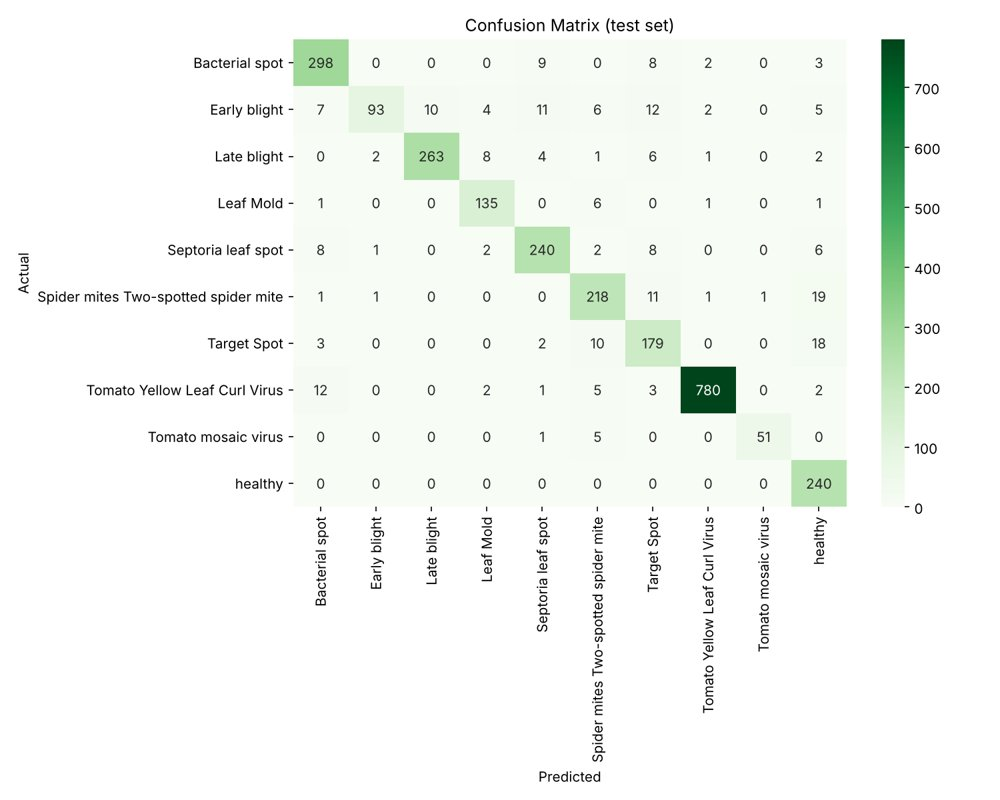

In [5]:
print(Path("outputs/classification_report_test.txt").read_text())
show("outputs/confusion_matrix_test.png", width=1000)

## Transfer learning vs. a CNN trained from scratch

In [6]:
import pandas as pd
pd.DataFrame([
    {"Model": "MobileNetV2 (transfer learning)", "Parameters": f"{summary['mobilenetv2']['params']:,}",
     "Test accuracy": f"{summary['mobilenetv2']['test_accuracy']*100:.2f}%"},
    {"Model": "Small CNN from scratch", "Parameters": f"{summary['baseline_cnn']['params']:,}",
     "Test accuracy": f"{summary['baseline_cnn']['test_accuracy']*100:.2f}%"},
])

,Model,Parameters,Test accuracy
0,MobileNetV2 (transfer learning),"2,270,794",91.33%
1,Small CNN from scratch,"94,538",85.37%


## Live predictions — computed right now by the loaded model
`samples/` holds 2 leaves per class from the **test split** (never seen in training). Green = correct, red = wrong.

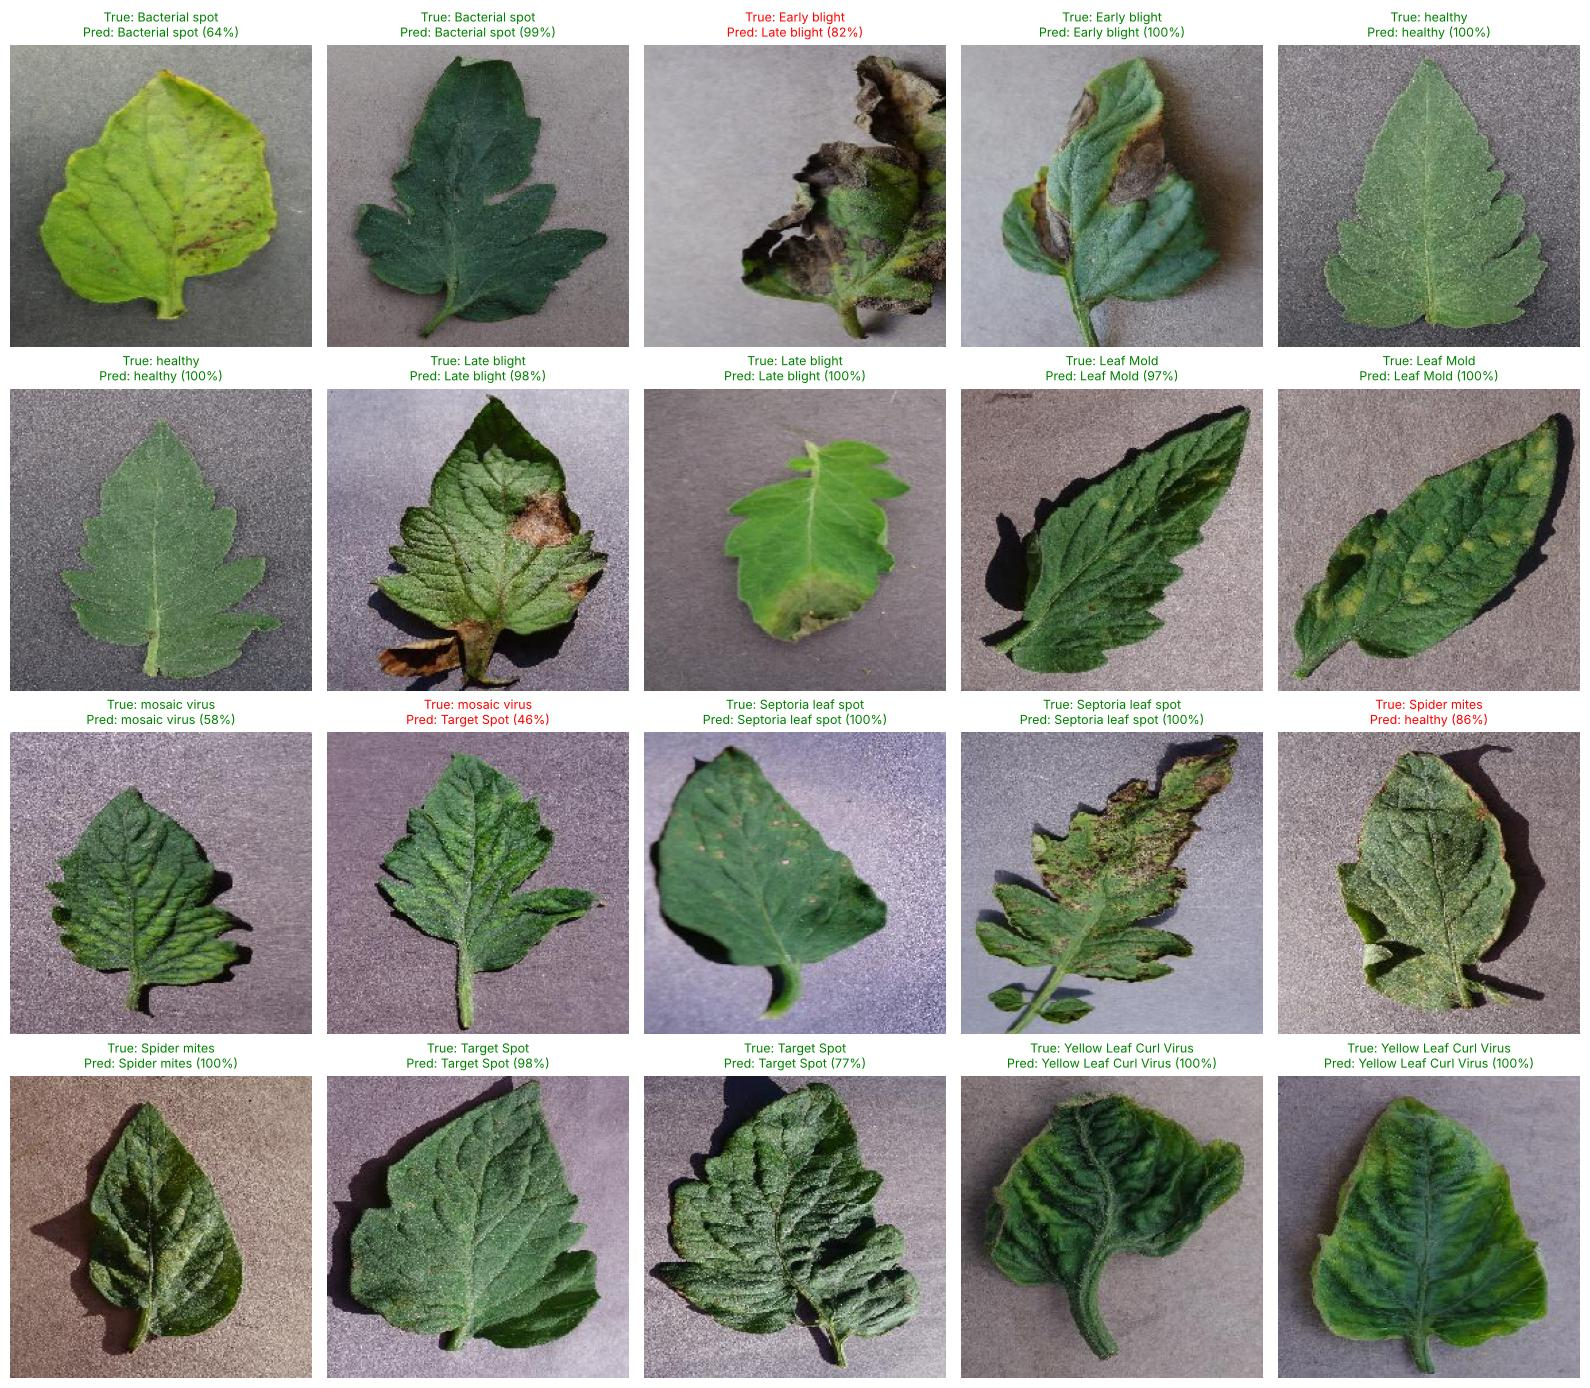

17/20 correct


In [7]:
def predict(path):
    img = tf.keras.utils.load_img(path, target_size=(224, 224))
    arr = np.expand_dims(tf.keras.utils.img_to_array(img), 0)   # raw 0-255: the model preprocesses internally
    return img, model.predict(arr, verbose=0)[0]

files = sorted(Path("samples").glob("*.jpg"))
truth = {Path(r["file"]).name: r["true"] for r in json.loads(Path("outputs/predictions.json").read_text())["samples"]}
fig, axes = plt.subplots(4, 5, figsize=(16, 14))
correct = 0
for ax, f in zip(axes.flat, files):
    img, probs = predict(f)
    pred = class_names[int(np.argmax(probs))]
    ok = pred == truth[f.name]; correct += ok
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"True: {short(truth[f.name])}\nPred: {short(pred)} ({probs.max()*100:.0f}%)",
                 fontsize=9, color="green" if ok else "red")
plt.tight_layout(); plt.show()
print(f"{correct}/{len(files)} correct")

## Grad-CAM — where is the model looking?
Red = the regions that pushed the model towards its answer. On a good prediction the heat sits on the lesions, not the background.

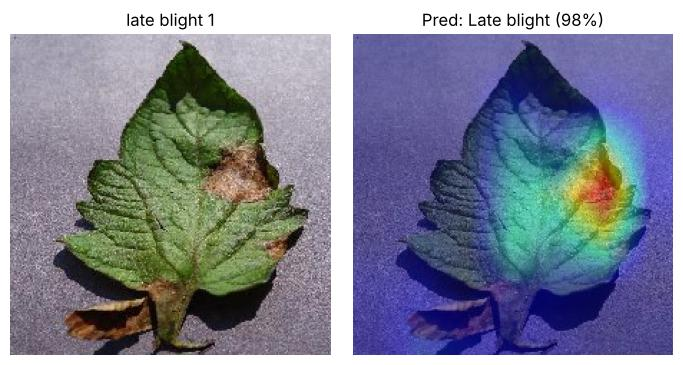

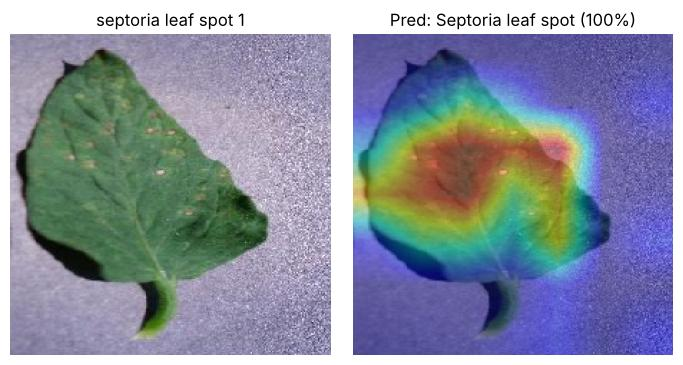

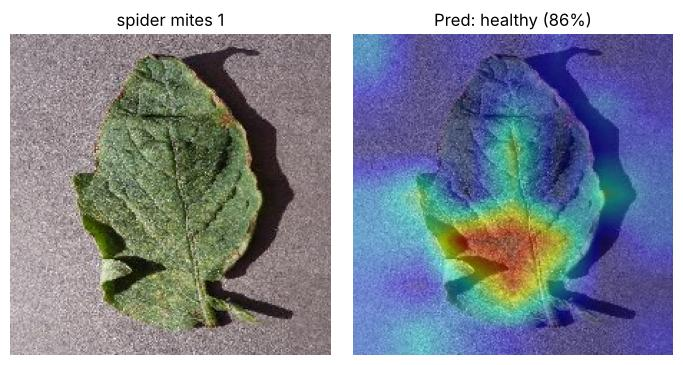

In [8]:
import cv2
from gradcam import make_cam

def gradcam_plot(path):
    img = tf.keras.utils.load_img(path, target_size=(224, 224))
    arr = np.expand_dims(tf.keras.utils.img_to_array(img), 0)
    pred, probs, cam = make_cam(model, arr)
    heat = cv2.applyColorMap(np.uint8(255 * cv2.resize(cam, (224, 224))), cv2.COLORMAP_JET)
    overlay = cv2.addWeighted(np.array(img), 0.6, cv2.cvtColor(heat, cv2.COLOR_BGR2RGB), 0.4, 0)
    fig, ax = plt.subplots(1, 2, figsize=(7, 3.6))
    ax[0].imshow(img); ax[0].set_title(Path(path).stem.replace("_", " ")); ax[0].axis("off")
    ax[1].imshow(overlay); ax[1].set_title(f"Pred: {short(class_names[pred])} ({probs[pred]*100:.0f}%)"); ax[1].axis("off")
    plt.tight_layout(); plt.show()

for name in ["late_blight_1", "septoria_leaf_spot_1", "spider_mites_1"]:
    gradcam_plot(f"samples/{name}.jpg")

## Try your own photo

In [9]:
# In Colab this opens a file picker; any tomato leaf photo works (one leaf, plain background works best).
try:
    from google.colab import files
    uploaded = files.upload()
    for name in uploaded:
        img, probs = predict(name)
        top = np.argsort(probs)[::-1][:3]
        plt.imshow(img); plt.axis("off"); plt.show()
        for i in top:
            print(f"{short(class_names[i]):28s} {probs[i]*100:6.2f}%")
        gradcam_plot(name)
except ImportError:
    print("Not running in Colab - use predict('path/to/leaf.jpg') instead.")

Not running in Colab - use predict('path/to/leaf.jpg') instead.


## The web app
Starts the Gradio app with a **public link** (open it on your phone). Upload a leaf → top-3 diseases + an info card (cause, symptoms, prevention). Stop the cell to shut it down.

In [ ]:
%run app.py